# `specmangle` demo/tutorial

First, we import a few modules we'll need.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
from astropy.nddata import StdDevUncertainty
from astropy.table import Table
from astropy.time import Time
from astropy import units as u
from specutils import Spectrum

from specmangle import mangle, Bandpass
from plot_helpers import plot_result, colors

Next, let's load some data to work with. For this example, we'll work with SN 2019szu, so that we can directly compare our methodology and results to the mangling procedure detailed by [Aamer, *et al.* (2025)](https://scixplorer.org/abs/2025MNRAS.541.2674A/abstract). See [Figure 1](https://academic.oup.com/view-large/figure/527145386/staf1113fig1.jpg) from that paper and its caption.

This spectrum was obtained by the Palomar Double Spectrograph (DBSP) on the 200" Hale Telescope on 2019-11-24. It is from the data associated with [Figure A1](https://iopscience.iop.org/article/10.3847/1538-4357/aca161#apjaca161f17) of [Chen, *et al.* (2023)](https://scixplorer.org/abs/2023ApJ...943...41C/abstract).

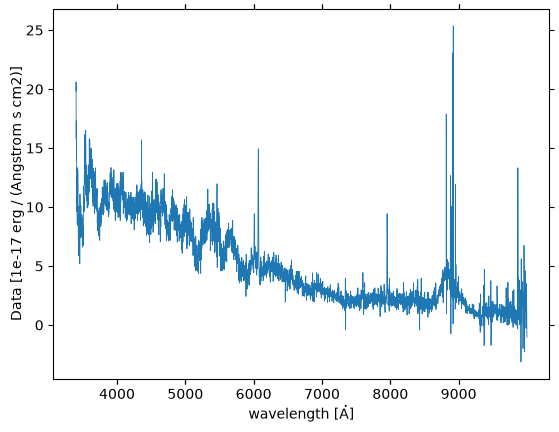

In [2]:
spec = Spectrum.read("data/2019szu_spectrum.ecsv")
spec.plot(lw=0.6)
plt.show()

For a first pass, let's just try a single photometric data point. All of the photometry for this object is derived from the data in Chen *et al.* (2023)'s [Table A3](https://iopscience.iop.org/article/10.3847/1538-4357/aca161#apjaca161t6).

In [3]:
phot = Table(
    rows=[
        ("Misc/Atlas.orange", 19.06, 0.18),
    ],
    names=["band", "mag", "mag_err"],
    units=[None, u.ABmag, u.mag],
)
phot

band,mag,mag_err
,mag(AB),mag
str17,float64,float64
Misc/Atlas.orange,19.06,0.18


Note the format of the photometry table above. It must have `"band"` and `"mag"` (and optionally `"mag_err"`) columns, and the entries of the `"band"` column should be SVO FPS bandpass specifier strings, unless you're going to define your own `Bandpass` objects. Note that while the units on the magnitude columns are not technically required, `specmangle` treats **all magnitudes as AB!** If your photometry data is on the Vega system (or anything else), you need to convert them to AB first. Such conversions are beyond the scope of this demo.

We're basically ready! Now we just call `mangle()` on our data, and then we'll take a look at the result.

In [4]:
result = mangle(spectrum=spec, photometry=phot)

In [5]:
result.photometry

band,mag,mag_err,used,coverage,skip_reason,synthetic_mag,synthetic_mag_err,residual
,mag(AB),mag,,,,,,
str17,float64,float64,bool,float64,str1,float64,float64,float64
Misc/Atlas.orange,19.06,0.18,True,1.0,,19.06,nan,0.0


The first thing we can see is that the fit has indeed used our single ATLAS $o$ data point (since the spectrum covers 100% of the bandpass), and that the synthetic magnitude resulting from the fit is exactly the input. This makes sense, as it is trivial to match any single band via simple scaling.

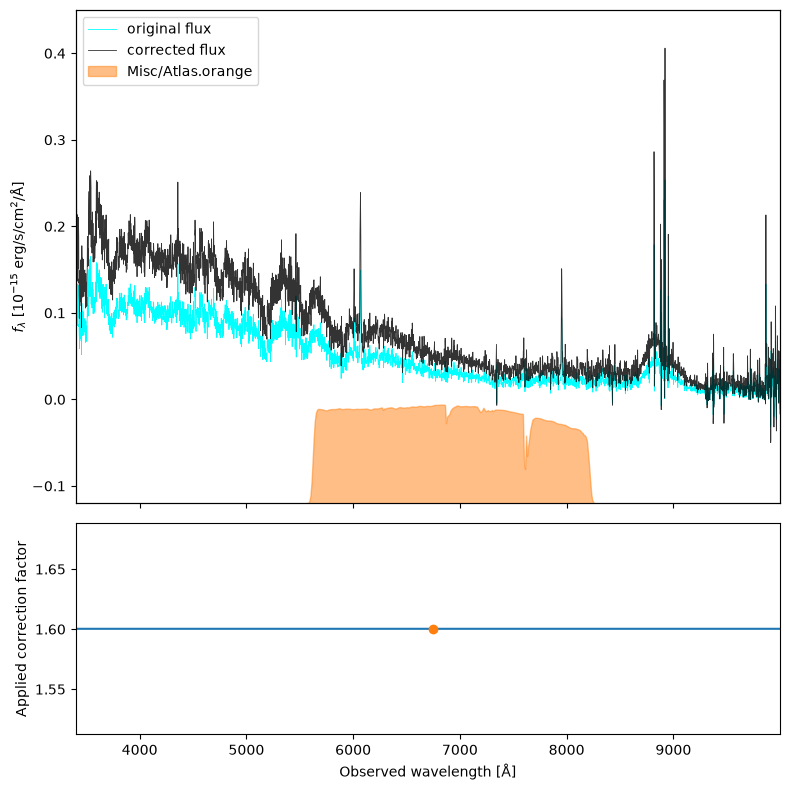

In [6]:
fig, axs = plot_result(result)
axs[0].set_ylim(-0.12, 0.45)
plt.tight_layout()
plt.show()

The lower panel shows the wavelength-dependent correction that has been applied. In this case, it's a uniform/constant scale factor across the entire spectrum. This makes the integrated spectrum reproduce the single given magnitude exactly.

But with mangling, we can do more than a single scalar. Let's try ZTF $g$ and $r$ simultaneously.

In [7]:
phot = Table(
    rows=[
        ("Palomar/ZTF.g", 18.59, 0.08),
        ("Palomar/ZTF.r", 18.89, 0.07),
    ],
    names=["band", "mag", "mag_err"],
    units=[None, u.ABmag, u.mag],
)

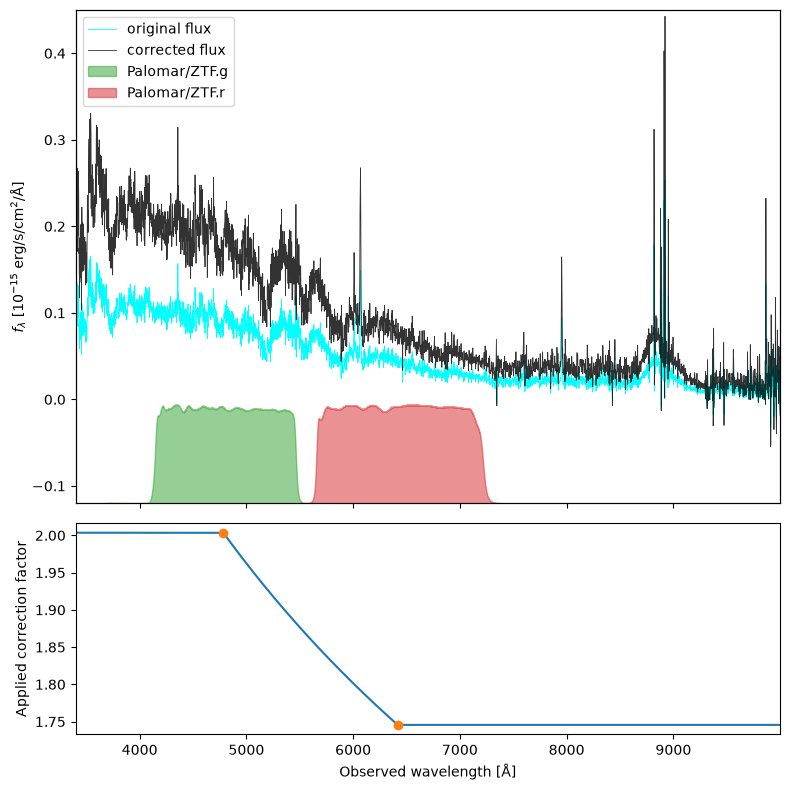

In [8]:
result = mangle(spectrum=spec, photometry=phot)
fig, axs = plot_result(result)
axs[0].set_ylim(-0.12, 0.45)
plt.tight_layout()
plt.show()

Now we see some actual wavelength-dependence in the applied correction. Between the effective wavelengths of the two bandpasses, the correction is linear in log-wavelength space. The values at either end are held fixed on either side to avoid guessing at what we don't know and thus introducing extrapolation error.

Let's try slightly more complex case. Now we switch to a well-observed SN Ia, 2013dy. We'll use a UV-to-NIR spectrum from the Hubble Space Telescope's STIS instrument, which generally has very good spectrophotometric (absolute flux) calibration already.

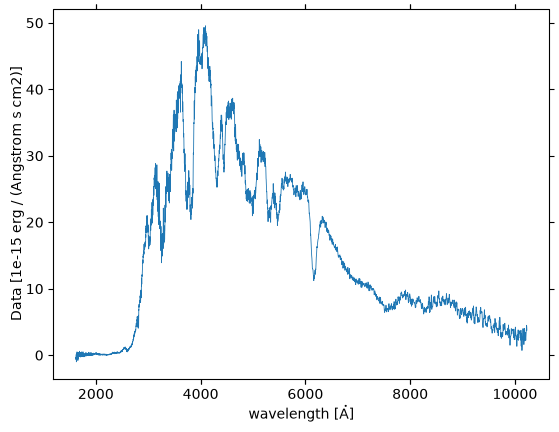

In [9]:
spec = Spectrum.read("data/2013dy_spectrum.ecsv")
spec.plot(lw=0.6)
plt.show()

This photometry comes from [Zhai, *et al.* (2016)](https://scixplorer.org/abs/2016AJ....151..125Z/abstract). Specifically, the *UBVRI* points are from [row 3 of J/AJ/151/125/table2](https://vizier.cds.unistra.fr/viz-bin/VizieR-5?-ref=VIZ6ad18dba94882&-out.add=.&-source=J/AJ/151/125/table2&recno=3), and the UVOT data are interpolated from [J/AJ/151/125/table3](https://vizier.cds.unistra.fr/viz-bin/VizieR-3?-source=J/AJ/151/125/table3). Recall that we need AB magnitudes, and these are all reported in the Vega system, so we need to convert them.

In [10]:
phot = Table(
    # We'll exclude UVW1 and UVw2 due to their red leaks and because
    # there's not that much UV flux in this spectrum anyway, so one UV
    # band (UVM2) is plenty in order to constrain that region.
    rows=[
        # ('Swift/UVOT.UVW2_trn', 16.30+1.73, 0.10),
        ('Swift/UVOT.UVM2_trn', 17.75+1.69, 0.15),
        # ('Swift/UVOT.UVW1_trn', 14.59+1.51, 0.07),
        ('Swift/UVOT.U_trn',    12.92+1.02, 0.05),
        ('Swift/UVOT.B_trn',    13.28-0.13, 0.05),
        # ('Swift/UVOT.V_trn',    13.02-0.01, 0.05),
        # ("GCPD/Johnson.U",   12.89+0.79, 0.05),
        # ("GCPD/Johnson.B",   13.28-0.09, 0.05),
        ("GCPD/Johnson.V",   12.96+0.02, 0.05),
        ("GCPD/Cousins.R",   12.85+0.21, 0.05),
        ("GCPD/Cousins.I",   12.96+0.45, 0.05),
    ],
    names=["band", "mag", "mag_err"],
    units=[None, u.ABmag, u.mag],
)

This time, since the wavelength space is much better-sampled by these bands, we will impose a non-zero `smoothness`, which penalizes changes in slope between adjacent spline anchors. Otherwise there is a good chance it would over-optimize and we would end up with an unrealistically wiggly correction. The `smoothness` parameter can and should be experimented with to achieve desired results, especially when using many photometric bands at once. Here's we'll use a very modest value of 0.1.

In [11]:
result = mangle(spec, phot, smoothness=0.1)

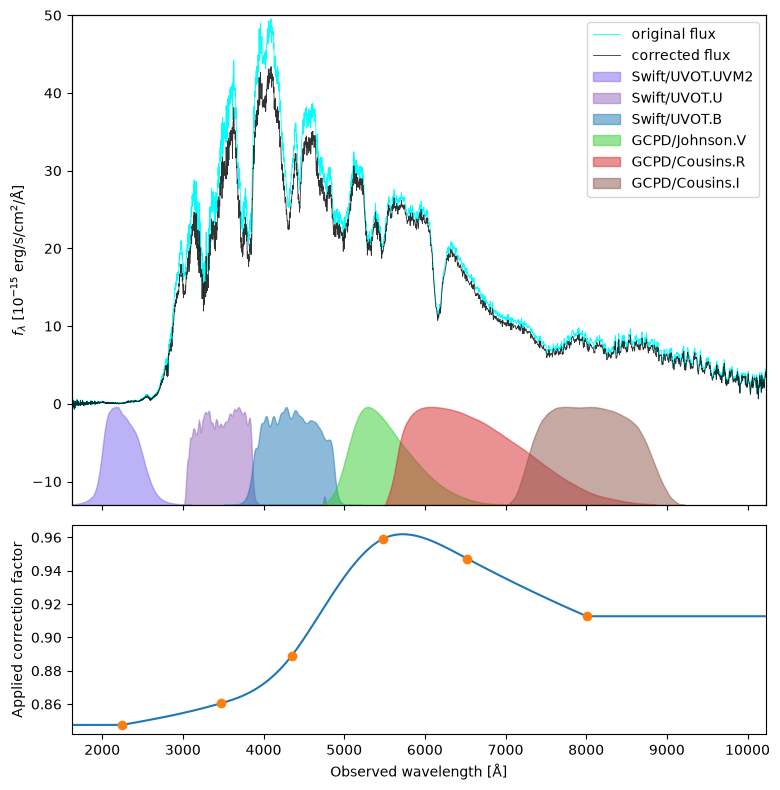

In [12]:
fig, axs = plot_result(result)
axs[0].set_ylim(-13, 50)
plt.tight_layout()
plt.show()

In [13]:
result.photometry

band,mag,mag_err,used,coverage,skip_reason,synthetic_mag,synthetic_mag_err,residual
,mag(AB),mag,,,,,,
str19,float64,float64,bool,float64,str1,float64,float64,float64
Swift/UVOT.UVM2_trn,19.44,0.15,True,0.9999028742636568,,19.44076171576923,nan,0.000761715769229454
Swift/UVOT.U_trn,13.94,0.05,True,1.0,,13.940070489555625,nan,7.048955562538595e-05
Swift/UVOT.B_trn,13.149999999999999,0.05,True,1.0,,13.149092170392226,nan,-0.0009078296077724701
GCPD/Johnson.V,12.98,0.05,True,1.0,,12.981411991025464,nan,0.0014119910254635215
GCPD/Cousins.R,13.06,0.05,True,1.0,,13.05942901213987,nan,-0.0005709878601312113
GCPD/Cousins.I,13.41,0.05,True,1.0,,13.409911702811524,nan,-8.829718847636059e-05


With `smoothness=0.1`, we see that our correction is both well-behaved and that our residuals are very small ($\lesssim0.1$ mmag) across the board. The correction factor is also consistently fairly close to 1, which makes sense given STIS' "out-of-the-box" spectrophotometric accuracacy.

Check out [the docs](https://specmangle.readthedocs.io/en/latest/) or the [GitHub repository](https://github.com/cgobat/specmangle) for more!